# 08 — Toronto Bike Share heat-event comparison

## Purpose

This notebook adds an **observed active-mobility layer** to the Toronto heat
accessibility proof-of-concept.

It compares Bike Share activity on:

- **25 July 2025** — heat-event Friday
- **18 July 2025** — matched Friday before
- **1 August 2025** — matched Friday after

The 2025 monthly Toronto Bike Share files use the following published schema:

- `Trip_Id`
- `Trip_Duration`
- `Start_Station_Id`
- `Start_Time`
- `Start_Station_Name`
- `End_Station_Id`
- `End_Time`
- `End_Station_Name`
- `Bike_Id`
- `User_Type`
- `Bike_Model`

This notebook uses that schema directly.

Main outputs:

1. citywide daily trip totals;
2. hourly ridership profiles;
3. afternoon activity;
4. trip-duration comparison;
5. trips touching the U of T thermal pilot;
6. pilot-area station activity;
7. cleaned event/reference trip extracts for Notebook 09.

Bike Share is treated as an **observed active-mobility response layer**, not as
direct validation of pedestrian accessibility.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and paths

In [1]:
from pathlib import Path
import re
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from shapely.geometry import box

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

BIKE_RAW = TORONTO_RAW / "bikeshare"
BIKE_INTERIM = TORONTO_INTERIM / "bikeshare"
BIKE_OUTPUTS = TORONTO_OUTPUTS / "bikeshare"

for folder in [
    BIKE_RAW,
    BIKE_INTERIM,
    BIKE_OUTPUTS,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Project root:", PROJECT_ROOT)
print("Bike Share raw:", BIKE_RAW)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
Bike Share raw: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/bikeshare


## 2. Event and matched reference dates

In [2]:
EVENT_DATE = pd.Timestamp("2025-07-25")

REFERENCE_DATES = [
    pd.Timestamp("2025-07-18"),
    pd.Timestamp("2025-08-01"),
]

STUDY_DATES = [
    *REFERENCE_DATES,
    EVENT_DATE,
]

for date in STUDY_DATES:
    print(date.date(), date.day_name())

2025-07-18 Friday
2025-08-01 Friday
2025-07-25 Friday


## 3. Query Toronto Open Data CKAN

In [3]:
CKAN_BASE = (
    "https://ckan0.cf.opendata.inter.prod-toronto.ca"
)

PACKAGE_ID = (
    "bike-share-toronto-ridership-data"
)

response = requests.get(
    CKAN_BASE + "/api/3/action/package_show",
    params={"id": PACKAGE_ID},
    timeout=60,
)

response.raise_for_status()

package_json = response.json()

if not package_json.get("success", False):
    raise RuntimeError(
        "Toronto CKAN package query failed."
    )

resources = pd.DataFrame(
    package_json["result"]["resources"]
)

display(
    resources[
        [
            c
            for c in [
                "name",
                "format",
                "url",
                "last_modified",
            ]
            if c in resources.columns
        ]
    ]
)

,name,format,url,last_modified
0,bikeshare-ridership-readme,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-12T14:38:55
1,bikeshare-ridership-2014-2015,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-11T15:42:55
2,bikeshare-ridership-2016,XLSX,https://ckan0.cf.opendata.inter.prod-toronto.c...,2022-04-11T15:48:24
3,bikeshare-ridership-2017.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:48:57
4,bikeshare-ridership-2018.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:52:05
5,bikeshare-ridership-2019.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:55:06
6,bikeshare-ridership-2020.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T15:55:11
7,bikeshare-ridership-2021.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2022-04-11T16:01:24
8,bikeshare-ridership-2022.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2023-01-18T17:36:31
9,bikeshare-ridership-2023.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...,2024-01-09T17:24:07


## 4. Select and cache the 2025 ridership resource

In [4]:
resource_2025 = resources[
    resources["name"]
    .astype(str)
    .str.contains(
        "2025",
        case=False,
        na=False,
    )
].copy()

if resource_2025.empty:
    raise RuntimeError(
        "No 2025 Bike Share resource found."
    )

display(
    resource_2025[
        [
            c
            for c in [
                "name",
                "format",
                "url",
            ]
            if c in resource_2025.columns
        ]
    ]
)

selected_resource = (
    resource_2025.iloc[0]
)

RIDERSHIP_2025_URL = (
    selected_resource["url"]
)

ZIP_PATH = (
    BIKE_RAW
    / "bike_share_ridership_2025.zip"
)

if not ZIP_PATH.exists():

    print(
        "Downloading 2025 Bike Share ridership..."
    )

    download = requests.get(
        RIDERSHIP_2025_URL,
        timeout=300,
    )

    download.raise_for_status()

    ZIP_PATH.write_bytes(
        download.content
    )

    print("Saved:", ZIP_PATH)

else:

    print(
        "Using cached file:",
        ZIP_PATH,
    )

,name,format,url
11,bikeshare-ridership-2025.zip,ZIP,https://opendata.toronto.ca/toronto.parking.au...


Using cached file: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/raw/bikeshare/bike_share_ridership_2025.zip


## 5. Inspect archive contents

In [5]:
with zipfile.ZipFile(
    ZIP_PATH,
    "r",
) as archive:

    archive_names = archive.namelist()

csv_names = [
    name
    for name in archive_names
    if name.lower().endswith(".csv")
]

for name in csv_names:
    print("-", name)

- bikeshare_2025_12.csv
- bikeshare_2025_01.csv
- bikeshare_2025_02.csv
- bikeshare_2025_03.csv
- bikeshare_2025_04.csv
- bikeshare_2025_05.csv
- bikeshare_2025_06.csv
- bikeshare_2025_07.csv
- bikeshare_2025_08.csv
- bikeshare_2025_09.csv
- bikeshare_2025_10.csv
- bikeshare_2025_11.csv


## 6. Identify July and August 2025 monthly files

In [6]:
july_candidates = [
    name
    for name in csv_names
    if re.search(
        r"2025[-_ ]?0?7",
        name,
        flags=re.IGNORECASE,
    )
]

august_candidates = [
    name
    for name in csv_names
    if re.search(
        r"2025[-_ ]?0?8",
        name,
        flags=re.IGNORECASE,
    )
]

if not july_candidates:
    raise RuntimeError(
        "Could not identify July 2025 CSV."
    )

if not august_candidates:
    raise RuntimeError(
        "Could not identify August 2025 CSV."
    )

JULY_FILE = july_candidates[0]
AUGUST_FILE = august_candidates[0]

print("July file:", JULY_FILE)
print("August file:", AUGUST_FILE)

July file: bikeshare_2025_07.csv
August file: bikeshare_2025_08.csv


## 7. Read monthly CSVs using the actual 2025 schema

The files have a header row.

`cp1252` is used because some station names contain non-UTF-8 characters.

In [7]:
EXPECTED_COLUMNS = [
    "Trip_Id",
    "Trip_Duration",
    "Start_Station_Id",
    "Start_Time",
    "Start_Station_Name",
    "End_Station_Id",
    "End_Time",
    "End_Station_Name",
    "Bike_Id",
    "User_Type",
    "Bike_Model",
]


def read_bikeshare_month(
    zip_path,
    member,
):

    with zipfile.ZipFile(
        zip_path,
        "r",
    ) as archive:

        with archive.open(
            member
        ) as handle:

            df = pd.read_csv(
                handle,
                encoding="cp1252",
                low_memory=False,
            )

    return df


july = read_bikeshare_month(
    ZIP_PATH,
    JULY_FILE,
)

august = read_bikeshare_month(
    ZIP_PATH,
    AUGUST_FILE,
)

print(
    "July rows:",
    f"{len(july):,}",
)

print(
    "August rows:",
    f"{len(august):,}",
)

display(
    july.head()
)

July rows: 1,192,062
August rows: 1,164,697


,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
0,37921894,1596,7175,2025-07-01 00:02:53,HTO Park (Queens Quay W),7175.0,2025-07-01 00:29:29,HTO Park (Queens Quay W),1757,Casual,ICONIC
1,37921863,409,7267,2025-07-01 00:00:12,Dundas St E / Pembroke St,7021.0,2025-07-01 00:07:01,Dundas St E / Pembroke St,6269,Member,ICONIC
2,37921859,296,7240,2025-07-01 00:00:00,Bloor St W / Shaw St - SMART,7691.0,2025-07-01 00:04:56,Bloor St W / Shaw St - SMART,9493,Member,ICONIC
3,37921870,831,7712,2025-07-01 00:00:35,Queen St W / Shaw St,7929.0,2025-07-01 00:14:26,Queen St W / Shaw St,6148,Casual,ICONIC
4,37921891,426,7121,2025-07-01 00:02:33,Jarvis St / Dundas St E,7713.0,2025-07-01 00:09:39,Jarvis St / Dundas St E,582,Casual,ICONIC


## 8. Validate schema

In [8]:
print(
    "July columns:",
    list(july.columns),
)

missing_july = [
    column
    for column in EXPECTED_COLUMNS
    if column not in july.columns
]

missing_august = [
    column
    for column in EXPECTED_COLUMNS
    if column not in august.columns
]

if missing_july:
    raise RuntimeError(
        f"July missing columns: {missing_july}"
    )

if missing_august:
    raise RuntimeError(
        f"August missing columns: {missing_august}"
    )

print(
    "✓ Expected 2025 Bike Share schema confirmed."
)

July columns: ['Trip_Id', 'Trip_Duration', 'Start_Station_Id', 'Start_Time', 'Start_Station_Name', 'End_Station_Id', 'End_Time', 'End_Station_Name', 'Bike_Id', 'User_Type', 'Bike_Model']
✓ Expected 2025 Bike Share schema confirmed.


## 9. Standardize names and combine months

In [9]:
RENAME = {
    "Trip_Id": "trip_id",
    "Trip_Duration": "duration_seconds",
    "Start_Station_Id": "start_station_id",
    "Start_Time": "start_datetime",
    "Start_Station_Name": "start_station_name",
    "End_Station_Id": "end_station_id",
    "End_Time": "end_datetime",
    "End_Station_Name": "end_station_name",
    "Bike_Id": "bike_id",
    "User_Type": "user_type",
    "Bike_Model": "bike_model",
}

july = july.rename(
    columns=RENAME
)

august = august.rename(
    columns=RENAME
)

trips = pd.concat(
    [
        july,
        august,
    ],
    ignore_index=True,
)

print(
    "Combined rows:",
    f"{len(trips):,}",
)

Combined rows: 2,356,759


## 10. Parse timestamps and numeric fields

In [10]:
trips[
    "start_datetime"
] = pd.to_datetime(
    trips[
        "start_datetime"
    ],
    errors="coerce",
)

trips[
    "end_datetime"
] = pd.to_datetime(
    trips[
        "end_datetime"
    ],
    errors="coerce",
)

trips[
    "duration_seconds"
] = pd.to_numeric(
    trips[
        "duration_seconds"
    ],
    errors="coerce",
)

trips[
    "date"
] = (
    trips[
        "start_datetime"
    ]
    .dt.normalize()
)

trips[
    "hour"
] = (
    trips[
        "start_datetime"
    ]
    .dt.hour
)

trips[
    "start_station_id_join"
] = (
    trips[
        "start_station_id"
    ]
    .astype(str)
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .str.strip()
)

trips[
    "end_station_id_join"
] = (
    trips[
        "end_station_id"
    ]
    .astype(str)
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .str.strip()
)

print(
    "Valid start timestamps:",
    f"{trips['start_datetime'].notna().sum():,}",
)

print(
    "Valid end timestamps:",
    f"{trips['end_datetime'].notna().sum():,}",
)

print(
    "Start date range:",
    trips["start_datetime"].min(),
    "to",
    trips["start_datetime"].max(),
)

Valid start timestamps: 2,356,759
Valid end timestamps: 2,356,491
Start date range: 2025-07-01 00:00:00 to 2025-08-31 23:59:53


## 11. Inspect cleaned trip records

In [11]:
display(
    trips[
        [
            "trip_id",
            "duration_seconds",
            "start_datetime",
            "start_station_name",
            "start_station_id_join",
            "end_datetime",
            "end_station_name",
            "end_station_id_join",
            "user_type",
            "bike_model",
        ]
    ].head(
        10
    )
)

print()
print("User types:")
print(
    trips[
        "user_type"
    ].value_counts(
        dropna=False
    )
)

print()
print("Bike models:")
print(
    trips[
        "bike_model"
    ].value_counts(
        dropna=False
    )
)

,trip_id,duration_seconds,start_datetime,start_station_name,start_station_id_join,end_datetime,end_station_name,end_station_id_join,user_type,bike_model
0,37921894,1596,2025-07-01 00:02:53,HTO Park (Queens Quay W),7175,2025-07-01 00:29:29,HTO Park (Queens Quay W),7175,Casual,ICONIC
1,37921863,409,2025-07-01 00:00:12,Dundas St E / Pembroke St,7267,2025-07-01 00:07:01,Dundas St E / Pembroke St,7021,Member,ICONIC
2,37921859,296,2025-07-01 00:00:00,Bloor St W / Shaw St - SMART,7240,2025-07-01 00:04:56,Bloor St W / Shaw St - SMART,7691,Member,ICONIC
3,37921870,831,2025-07-01 00:00:35,Queen St W / Shaw St,7712,2025-07-01 00:14:26,Queen St W / Shaw St,7929,Casual,ICONIC
4,37921891,426,2025-07-01 00:02:33,Jarvis St / Dundas St E,7121,2025-07-01 00:09:39,Jarvis St / Dundas St E,7713,Casual,ICONIC
5,37921865,826,2025-07-01 00:00:21,Amroth Ave / Danforth Ave,7659,2025-07-01 00:14:07,Amroth Ave / Danforth Ave,7427,Casual,EFIT G5
6,37921860,807,2025-07-01 00:00:01,University Ave / Pearl St,7916,2025-07-01 00:13:28,University Ave / Pearl St,7267,Casual,ICONIC
7,37921880,2407,2025-07-01 00:01:42,Queen St E / Berkeley St,7110,2025-07-01 00:41:49,Queen St E / Berkeley St,7302,Casual,EFIT G5
8,37921896,378,2025-07-01 00:03:07,Beverley St / Dundas St W,7027,2025-07-01 00:09:25,Beverley St / Dundas St W,7038,Member,ICONIC
9,37921867,854,2025-07-01 00:00:23,Dalton Rd / Bloor St W,7061,2025-07-01 00:14:37,Dalton Rd / Bloor St W,7324,Casual,ICONIC



User types:
user_type
Member    1537067
Casual     819692
Name: count, dtype: int64

Bike models:
bike_model
ICONIC     1898757
EFIT        263478
EFIT G5     194524
Name: count, dtype: int64


## 12. Extract heat-event and reference days

In [12]:
study_trips = trips[
    trips[
        "date"
    ].isin(
        STUDY_DATES
    )
].copy()

study_trips[
    "day_type"
] = np.where(
    study_trips[
        "date"
    ] == EVENT_DATE,
    "heat_event",
    "reference",
)

print(
    "Study-date trips:",
    f"{len(study_trips):,}",
)

display(
    study_trips[
        "date"
    ]
    .value_counts()
    .sort_index()
    .rename("trips")
    .to_frame()
)

Study-date trips: 118,657


,trips
date,
2025-07-18,41710
2025-07-25,37683
2025-08-01,39264


## 13. Citywide daily ridership comparison

In [13]:
daily_counts = (
    study_trips
    .groupby("date")
    .size()
    .rename("trips")
    .reset_index()
)

daily_counts[
    "day_type"
] = np.where(
    daily_counts[
        "date"
    ] == EVENT_DATE,
    "heat_event",
    "reference",
)

display(daily_counts)

reference_mean = float(
    daily_counts.loc[
        daily_counts[
            "day_type"
        ] == "reference",
        "trips",
    ].mean()
)

event_total = float(
    daily_counts.loc[
        daily_counts[
            "day_type"
        ] == "heat_event",
        "trips",
    ].iloc[0]
)

citywide_change_pct = (
    (
        event_total
        - reference_mean
    )
    / reference_mean
    * 100
)

print(
    "Citywide event trips:",
    event_total,
)

print(
    "Citywide reference mean:",
    reference_mean,
)

print(
    "Citywide change (%):",
    round(
        citywide_change_pct,
        2,
    ),
)

,date,trips,day_type
0,2025-07-18,41710,reference
1,2025-07-25,37683,heat_event
2,2025-08-01,39264,reference


Citywide event trips: 37683.0
Citywide reference mean: 40487.0
Citywide change (%): -6.93


## 14. Hourly citywide profiles

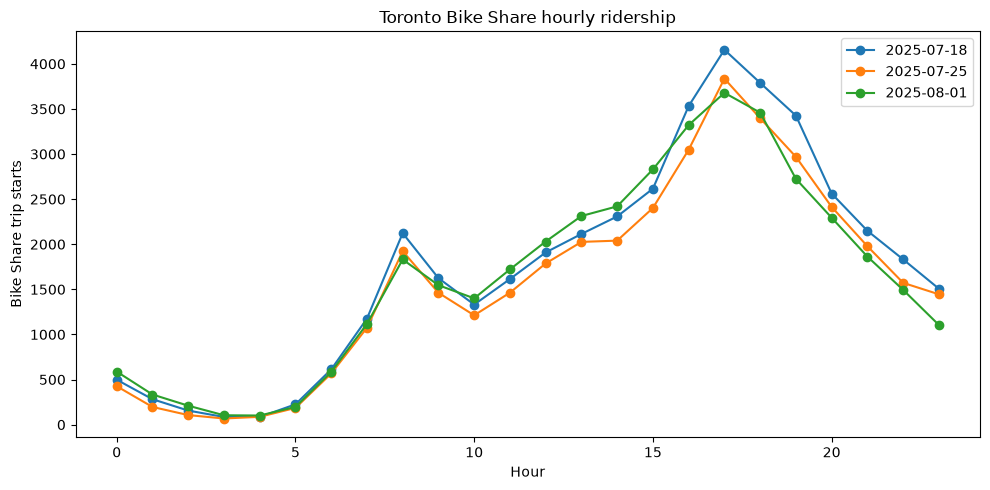

In [14]:
hourly = (
    study_trips
    .groupby(
        [
            "date",
            "hour",
        ]
    )
    .size()
    .rename("trips")
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

for date in sorted(
    hourly[
        "date"
    ].dropna().unique()
):

    subset = hourly[
        hourly[
            "date"
        ] == date
    ]

    ax.plot(
        subset["hour"],
        subset["trips"],
        marker="o",
        label=str(
            pd.Timestamp(
                date
            ).date()
        ),
    )

ax.set_xlabel("Hour")
ax.set_ylabel("Bike Share trip starts")
ax.set_title(
    "Toronto Bike Share hourly ridership"
)
ax.legend()

plt.tight_layout()
plt.show()

## 15. Afternoon comparison

Afternoon window: **12:00–18:59**

In [15]:
study_trips[
    "is_afternoon"
] = study_trips[
    "hour"
].between(
    12,
    18,
    inclusive="both",
)

afternoon_summary = (
    study_trips
    .groupby("date")
    .agg(
        total_trips=(
            "date",
            "size",
        ),
        afternoon_trips=(
            "is_afternoon",
            "sum",
        ),
    )
    .reset_index()
)

afternoon_summary[
    "afternoon_share_pct"
] = (
    afternoon_summary[
        "afternoon_trips"
    ]
    / afternoon_summary[
        "total_trips"
    ]
    * 100
)

display(
    afternoon_summary
)

,date,total_trips,afternoon_trips,afternoon_share_pct
0,2025-07-18,41710,20424,48.966675
1,2025-07-25,37683,18536,49.189290
2,2025-08-01,39264,20052,51.069682


## 16. Trip-duration comparison

In [16]:
plausible = study_trips[
    "duration_seconds"
].between(
    60,
    4 * 3600,
)

duration_summary = (
    study_trips[
        plausible
    ]
    .groupby("date")[
        "duration_seconds"
    ]
    .agg(
        [
            "count",
            "mean",
            "median",
        ]
    )
    .reset_index()
)

duration_summary[
    "mean_minutes"
] = (
    duration_summary[
        "mean"
    ]
    / 60
)

duration_summary[
    "median_minutes"
] = (
    duration_summary[
        "median"
    ]
    / 60
)

display(
    duration_summary
)

,date,count,mean,median,mean_minutes,median_minutes
0,2025-07-18,41539,1061.887479,747.0,17.698125,12.450000
1,2025-07-25,37589,1020.511479,713.0,17.008525,11.883333
2,2025-08-01,39141,1079.308960,738.0,17.988483,12.300000


## 17. Recreate the U of T 2 km × 2 km pilot

In [17]:
campus_center = gpd.read_file(
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
)

TARGET_CRS = campus_center.crs

PILOT_HALF_WIDTH_M = 1000

campus_x = float(
    campus_center.geometry.x.iloc[0]
)

campus_y = float(
    campus_center.geometry.y.iloc[0]
)

pilot_geometry = box(
    campus_x - PILOT_HALF_WIDTH_M,
    campus_y - PILOT_HALF_WIDTH_M,
    campus_x + PILOT_HALF_WIDTH_M,
    campus_y + PILOT_HALF_WIDTH_M,
)

pilot_area = gpd.GeoDataFrame(
    {
        "name": [
            "UOFT_PILOT"
        ],
    },
    geometry=[
        pilot_geometry
    ],
    crs=TARGET_CRS,
)

print(
    "Pilot area km²:",
    pilot_area.geometry.area.iloc[0]
    / 1_000_000,
)

Pilot area km²: 4.0


## 18. Retrieve Bike Share station coordinates from GBFS

In [18]:
GBFS_ROOT_CANDIDATES = [
    (
        "https://tor.publicbikesystem.net/"
        "ube/gbfs/v1/gbfs.json"
    ),
    (
        "https://tor.publicbikesystem.net/"
        "customer/gbfs/v2/gbfs.json"
    ),
]

gbfs_root = None
gbfs_root_url = None

for candidate in GBFS_ROOT_CANDIDATES:

    try:

        test = requests.get(
            candidate,
            timeout=30,
        )

        if test.ok:

            gbfs_root = test.json()
            gbfs_root_url = candidate
            break

    except Exception:
        pass

if gbfs_root is None:
    raise RuntimeError(
        "Could not retrieve Toronto Bike Share GBFS feed."
    )

print(
    "GBFS root:",
    gbfs_root_url,
)

GBFS root: https://tor.publicbikesystem.net/ube/gbfs/v1/gbfs.json


## 19. Discover station-information feed

In [19]:
data_section = gbfs_root.get(
    "data",
    {}
)

if "en" in data_section:

    feeds = (
        data_section[
            "en"
        ].get(
            "feeds",
            []
        )
    )

else:

    feeds = (
        data_section.get(
            "feeds",
            []
        )
    )

station_info_url = None

for feed in feeds:

    if feed.get("name") == "station_information":

        station_info_url = feed.get("url")
        break

if station_info_url is None:
    raise RuntimeError(
        "GBFS station_information feed was not found."
    )

print(
    "Station information URL:",
    station_info_url,
)

Station information URL: https://toronto.publicbikesystem.net/customer/ube/gbfs/v1/en/station_information


## 20. Build station GeoDataFrame

In [20]:
station_response = requests.get(
    station_info_url,
    timeout=30,
)

station_response.raise_for_status()

station_json = (
    station_response.json()
)

station_df = pd.DataFrame(
    station_json[
        "data"
    ][
        "stations"
    ]
)

required_station_cols = {
    "station_id",
    "lat",
    "lon",
}

if not required_station_cols.issubset(
    station_df.columns
):
    raise RuntimeError(
        "GBFS station data are missing station_id/lat/lon."
    )

station_df[
    "station_id_join"
] = (
    station_df[
        "station_id"
    ]
    .astype(str)
    .str.strip()
)

station_gdf = gpd.GeoDataFrame(
    station_df,
    geometry=gpd.points_from_xy(
        station_df["lon"],
        station_df["lat"],
    ),
    crs=4326,
).to_crs(
    TARGET_CRS
)

print(
    "Current GBFS stations:",
    len(station_gdf),
)

Current GBFS stations: 1072


## 21. Identify stations inside the U of T pilot

In [21]:
stations_in_pilot = station_gdf[
    station_gdf.geometry.within(
        pilot_geometry
    )
    |
    station_gdf.geometry.touches(
        pilot_geometry
    )
].copy()

pilot_station_ids = set(
    stations_in_pilot[
        "station_id_join"
    ]
)

print(
    "Stations inside pilot:",
    len(
        pilot_station_ids
    ),
)

Stations inside pilot: 61


## 22. Flag trips touching the pilot

In [22]:
study_trips[
    "start_in_pilot"
] = study_trips[
    "start_station_id_join"
].isin(
    pilot_station_ids
)

study_trips[
    "end_in_pilot"
] = study_trips[
    "end_station_id_join"
].isin(
    pilot_station_ids
)

study_trips[
    "touches_pilot"
] = (
    study_trips[
        "start_in_pilot"
    ]
    |
    study_trips[
        "end_in_pilot"
    ]
)

pilot_trips = study_trips[
    study_trips[
        "touches_pilot"
    ]
].copy()

print(
    "Trips touching pilot:",
    f"{len(pilot_trips):,}",
)

Trips touching pilot: 20,643


## 23. Visualize pilot and stations

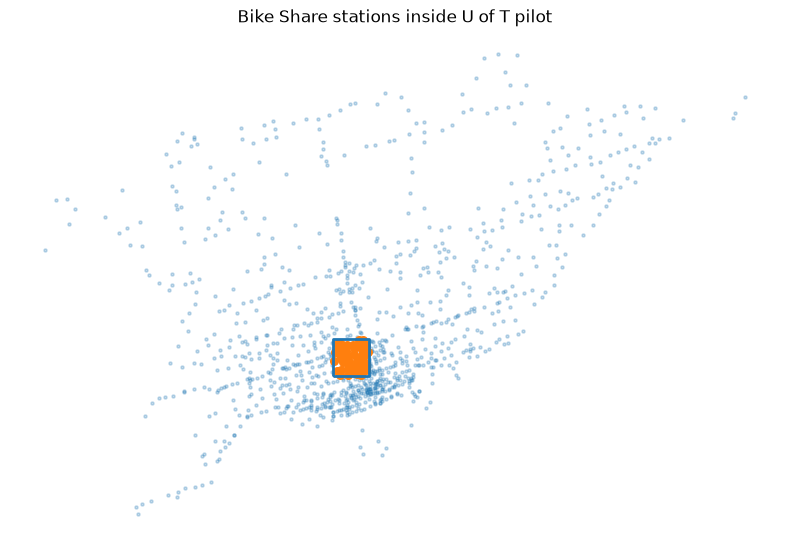

In [23]:
fig, ax = plt.subplots(
    figsize=(8, 8)
)

pilot_area.boundary.plot(
    ax=ax,
    linewidth=2.0,
)

station_gdf.plot(
    ax=ax,
    markersize=5,
    alpha=0.25,
)

stations_in_pilot.plot(
    ax=ax,
    markersize=30,
)

ax.set_title(
    "Bike Share stations inside U of T pilot"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 24. Pilot-area daily comparison

In [24]:
pilot_daily = (
    pilot_trips
    .groupby("date")
    .agg(
        touching_trips=(
            "date",
            "size",
        ),
        starts_in_pilot=(
            "start_in_pilot",
            "sum",
        ),
        ends_in_pilot=(
            "end_in_pilot",
            "sum",
        ),
    )
    .reset_index()
)

display(
    pilot_daily
)

pilot_reference_mean = float(
    pilot_daily.loc[
        pilot_daily[
            "date"
        ].isin(
            REFERENCE_DATES
        ),
        "touching_trips",
    ].mean()
)

pilot_event_total = float(
    pilot_daily.loc[
        pilot_daily[
            "date"
        ] == EVENT_DATE,
        "touching_trips",
    ].iloc[0]
)

pilot_change_pct = (
    (
        pilot_event_total
        - pilot_reference_mean
    )
    / pilot_reference_mean
    * 100
)

print(
    "Pilot event trips:",
    pilot_event_total,
)

print(
    "Pilot reference mean:",
    pilot_reference_mean,
)

print(
    "Pilot change (%):",
    round(
        pilot_change_pct,
        2,
    ),
)

,date,touching_trips,starts_in_pilot,ends_in_pilot
0,2025-07-18,7075,4274,4080
1,2025-07-25,6922,4240,3935
2,2025-08-01,6646,4012,3743


Pilot event trips: 6922.0
Pilot reference mean: 6860.5
Pilot change (%): 0.9


## 25. Pilot-area hourly comparison

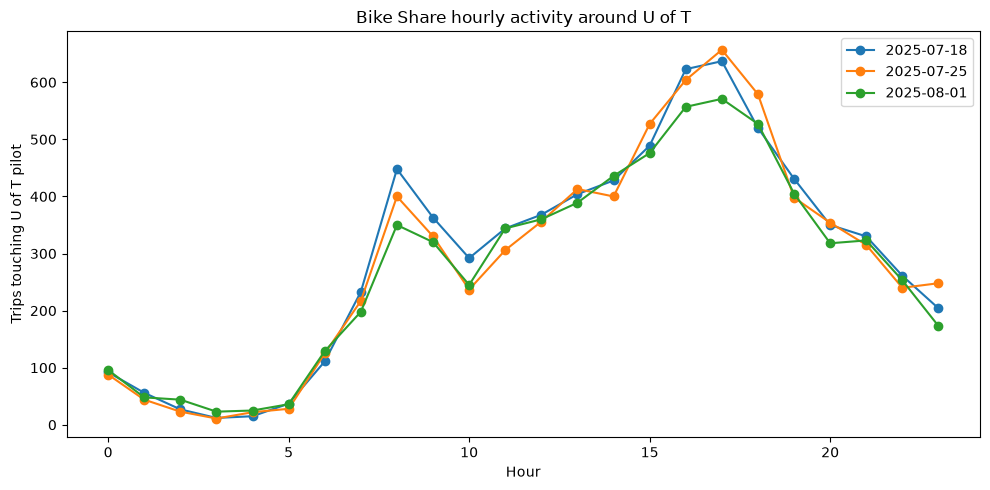

In [25]:
pilot_hourly = (
    pilot_trips
    .groupby(
        [
            "date",
            "hour",
        ]
    )
    .size()
    .rename("trips")
    .reset_index()
)

fig, ax = plt.subplots(
    figsize=(10, 5)
)

for date in sorted(
    pilot_hourly[
        "date"
    ].dropna().unique()
):

    subset = pilot_hourly[
        pilot_hourly[
            "date"
        ] == date
    ]

    ax.plot(
        subset["hour"],
        subset["trips"],
        marker="o",
        label=str(
            pd.Timestamp(
                date
            ).date()
        ),
    )

ax.set_xlabel("Hour")
ax.set_ylabel(
    "Trips touching U of T pilot"
)
ax.set_title(
    "Bike Share hourly activity around U of T"
)
ax.legend()

plt.tight_layout()
plt.show()

## 26. Station-level pilot activity

In [26]:
station_day_counts = (
    pilot_trips[
        pilot_trips[
            "start_in_pilot"
        ]
    ]
    .groupby(
        [
            "date",
            "start_station_id_join",
        ]
    )
    .size()
    .rename(
        "trip_starts"
    )
    .reset_index()
)

station_pivot = (
    station_day_counts
    .pivot_table(
        index="start_station_id_join",
        columns="date",
        values="trip_starts",
        fill_value=0,
    )
)

for date in STUDY_DATES:

    if date not in station_pivot.columns:
        station_pivot[date] = 0

station_pivot[
    "reference_mean"
] = station_pivot[
    REFERENCE_DATES
].mean(
    axis=1
)

station_pivot[
    "event"
] = station_pivot[
    EVENT_DATE
]

station_pivot[
    "change_pct"
] = np.where(
    station_pivot[
        "reference_mean"
    ] > 0,
    (
        station_pivot[
            "event"
        ]
        - station_pivot[
            "reference_mean"
        ]
    )
    / station_pivot[
        "reference_mean"
    ]
    * 100,
    np.nan,
)

display(
    station_pivot[
        [
            "reference_mean",
            "event",
            "change_pct",
        ]
    ]
    .sort_values(
        "change_pct"
    )
)

date,reference_mean,event,change_pct
start_station_id_join,,,
7600,32.0,0.0,-100.000000
7162,52.0,38.0,-26.923077
7170,40.0,31.0,-22.500000
7762,58.5,48.0,-17.948718
7006,239.0,198.0,-17.154812
7078,214.0,179.0,-16.355140
7273,85.0,72.0,-15.294118
7191,56.5,48.0,-15.044248
7667,61.0,52.0,-14.754098


## 27. Save clean outputs for Notebook 09

In [27]:
STUDY_TRIPS_PATH = (
    BIKE_INTERIM
    / "toronto_bikeshare_heat_reference_days.parquet"
)

PILOT_TRIPS_PATH = (
    BIKE_INTERIM
    / "uoft_pilot_bikeshare_heat_reference_days.parquet"
)

study_trips.to_parquet(
    STUDY_TRIPS_PATH,
    index=False,
)

pilot_trips.to_parquet(
    PILOT_TRIPS_PATH,
    index=False,
)

daily_counts.to_csv(
    BIKE_OUTPUTS
    / "citywide_daily_trip_counts.csv",
    index=False,
)

hourly.to_csv(
    BIKE_OUTPUTS
    / "citywide_hourly_trip_counts.csv",
    index=False,
)

afternoon_summary.to_csv(
    BIKE_OUTPUTS
    / "citywide_afternoon_summary.csv",
    index=False,
)

pilot_daily.to_csv(
    BIKE_OUTPUTS
    / "uoft_pilot_daily_trip_counts.csv",
    index=False,
)

pilot_hourly.to_csv(
    BIKE_OUTPUTS
    / "uoft_pilot_hourly_trip_counts.csv",
    index=False,
)

print(
    "Saved cleaned Bike Share outputs."
)

Saved cleaned Bike Share outputs.


## 28. Final summary

In [28]:
print(
    "Heat-event date:",
    EVENT_DATE.date(),
)

print(
    "Reference dates:",
    [
        date.date()
        for date in REFERENCE_DATES
    ],
)

print()

print(
    "Citywide event trips:",
    int(event_total),
)

print(
    "Citywide reference mean:",
    round(
        reference_mean,
        1,
    ),
)

print(
    "Citywide change (%):",
    round(
        citywide_change_pct,
        2,
    ),
)

print()

print(
    "Pilot event trips:",
    int(
        pilot_event_total
    ),
)

print(
    "Pilot reference mean:",
    round(
        pilot_reference_mean,
        1,
    ),
)

print(
    "Pilot change (%):",
    round(
        pilot_change_pct,
        2,
    ),
)

Heat-event date: 2025-07-25
Reference dates: [datetime.date(2025, 7, 18), datetime.date(2025, 8, 1)]

Citywide event trips: 37683
Citywide reference mean: 40487.0
Citywide change (%): -6.93

Pilot event trips: 6922
Pilot reference mean: 6860.5
Pilot change (%): 0.9


## Interpretation

This notebook now uses the actual 2025 Bike Share schema directly.

The key questions are:

- Was Bike Share activity on 25 July different from the matched Fridays?
- Was the U of T pilot response stronger or weaker than the citywide response?
- Was any difference concentrated in the hot afternoon?
- Did some stations respond differently from others?

Important caveats remain:

- one heat-event day;
- two matched reference Fridays;
- current GBFS coordinates are used as a proxy for July 2025 station positions;
- Bike Share is not a direct proxy for walking;
- weather and system operations may confound ridership.

Continue to:

**`09_toronto_thermal_accessibility_bikeshare_link.ipynb`**